# WEEK 4 — z-TRANSFORM LABORATORY: POLES, ZEROS AND STABILITY

## INTRODUCTION

The z-transform is an important mathematical tool used in Digital Signal Processing (DSP) to analyze discrete-time signals and systems.

In this laboratory, we investigate poles, zeros, frequency response, inverse z-transform and system stability using Python and SciPy.

## OBJECTIVES

1. Find poles, zeros and frequency response of a transfer function.
2. Use residuez to obtain an inverse z-transform.
3. Understand the relationship between pole positions and system stability.
4. Design a simple resonator by placing poles.

## PRE-LAB QUESTIONS

### Question 1(a): Find the poles and determine stability

Given:

H(z) = 1 / (1 - 0.9z^-1 + 0.81z^-2)

The denominator is:

z² - 0.9z + 0.81 = 0

Using the quadratic formula:

z = [0.9 ± √(0.9² - 4(0.81))] / 2

The poles are:

p1 = 0.45 + 0.7794j

p2 = 0.45 - 0.7794j

The magnitude of each pole is approximately:

|p| = 0.9

Since both poles have magnitudes less than 1, they lie inside the unit circle.

Therefore, the system is STABLE.

### Question 1(b): Partial Fraction Expansion

Given:

X(z) = 1 / [(1 - 0.5z^-1)(1 - 0.25z^-1)]

Assume:

X(z) = A/(1 - 0.5z^-1) + B/(1 - 0.25z^-1)

Multiplying through by the denominator:

1 = A(1 - 0.25z^-1) + B(1 - 0.5z^-1)

Comparing coefficients:

A + B = 1

0.25A + 0.5B = 0

Solving:

A = 2

B = -1

Therefore:

X(z) = 2/(1 - 0.5z^-1) - 1/(1 - 0.25z^-1)

The partial fraction expansion is complete.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 4 DSP Laboratory")
print("Libraries imported successfully!")

Week 4 DSP Laboratory
Libraries imported successfully!


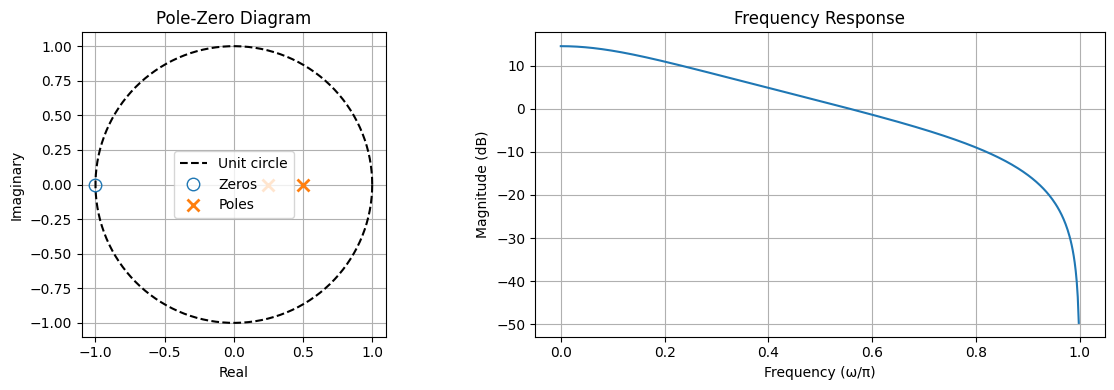

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [2]:
# Function to plot poles and zeros
def zplane(b, a, ax=None):

    # Calculate zeros, poles and gain
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    # Draw the unit circle
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", label="Unit circle")

    # Plot zeros and poles
    ax.plot(z.real, z.imag, "o", mfc="none",
            ms=9, label="Zeros")

    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="Poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.set_title("Pole-Zero Diagram")
    ax.grid()

    return z, p


# Transfer function coefficients
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot pole-zero diagram
z, p = zplane(b, a, ax1)

# Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

# Plot frequency response in decibels
ax2.plot(w/np.pi, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
ax2.set_xlabel("Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid()

plt.tight_layout()
plt.show()

# Check stability
print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

### Observation — Task 4.1

The pole-zero diagram was successfully plotted using the SciPy tf2zpk function.

The system has one zero at -1 and two poles at 0.5 and 0.25.

The frequency response was also plotted using the freqz function.

Both poles are located inside the unit circle because their magnitudes are less than 1.

The stability test returned True, confirming that the system is stable.

This experiment demonstrates how pole and zero positions can be used to analyze the behavior and stability of a digital system.

In [3]:
# TASK 4.2: Inverse z-Transform Using residuez

# Transfer function coefficients
b = [1]
a = [1, -0.75, 0.125]

# Find residues, poles and direct term
r, p, k = signal.residuez(b, a)

# Generate sample numbers from 0 to 9
n = np.arange(10)

# Calculate inverse z-transform using partial fractions
x_pf = sum(ri * (pi ** n) for ri, pi in zip(r, p)).real

# Generate unit impulse signal
impulse = np.zeros(10)
impulse[0] = 1

# Calculate output using lfilter
x_lfilter = signal.lfilter(b, a, impulse)

# Display results
print("Residues:", r)
print("Poles:", p)
print("Direct term:", k)

print("\nInverse z-transform using residuez:")
print(x_pf)

print("\nOutput using lfilter:")
print(x_lfilter)

print("\nDo the results match?")
print(np.allclose(x_pf, x_lfilter))

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []

Inverse z-transform using residuez:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Output using lfilter:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Do the results match?
True


In [5]:
# Repeat using the Task 4.1 system

b2 = [1, 1]
a2 = [1, -0.75, 0.125]

# Find residues and poles
r2, p2, k2 = signal.residuez(b2, a2)

# Calculate inverse z-transform
h_pf = sum(ri * (pi ** n) for ri, pi in zip(r2, p2)).real

# Calculate output using lfilter
h_lfilter = signal.lfilter(b2, a2, impulse)

# Theoretical impulse response
h_theory = 6 * (0.5 ** n) - 5 * (0.25 ** n)

print("Residues:", r2)
print("Poles:", p2)

print("\nUsing residuez:")
print(h_pf)

print("\nUsing lfilter:")
print(h_lfilter)

print("\nTheoretical impulse response:")
print(h_theory)

print("\nDo all results match?")
print(np.allclose(h_pf, h_lfilter) and np.allclose(h_pf, h_theory))

Residues: [-5.  6.]
Poles: [0.25 0.5 ]

Using residuez:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Theoretical impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Do all results match?
True
Residues: [-5.  6.]
Poles: [0.25 0.5 ]

Using residuez:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Theoretical impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Do all results match?
True


### Observation — Task 4.2

The residuez function was successfully used to calculate the inverse z-transform through partial fraction expansion.

The results obtained using residuez were compared with the output from the lfilter function.

Both methods produced matching results.

For the first system, the residues were 2 and -1, with poles at 0.5 and 0.25.

For the second system, the impulse response was also compared with the theoretical expression:

h(n) = 6(0.5)^n - 5(0.25)^n

The results matched, confirming that the inverse z-transform calculation was correct.

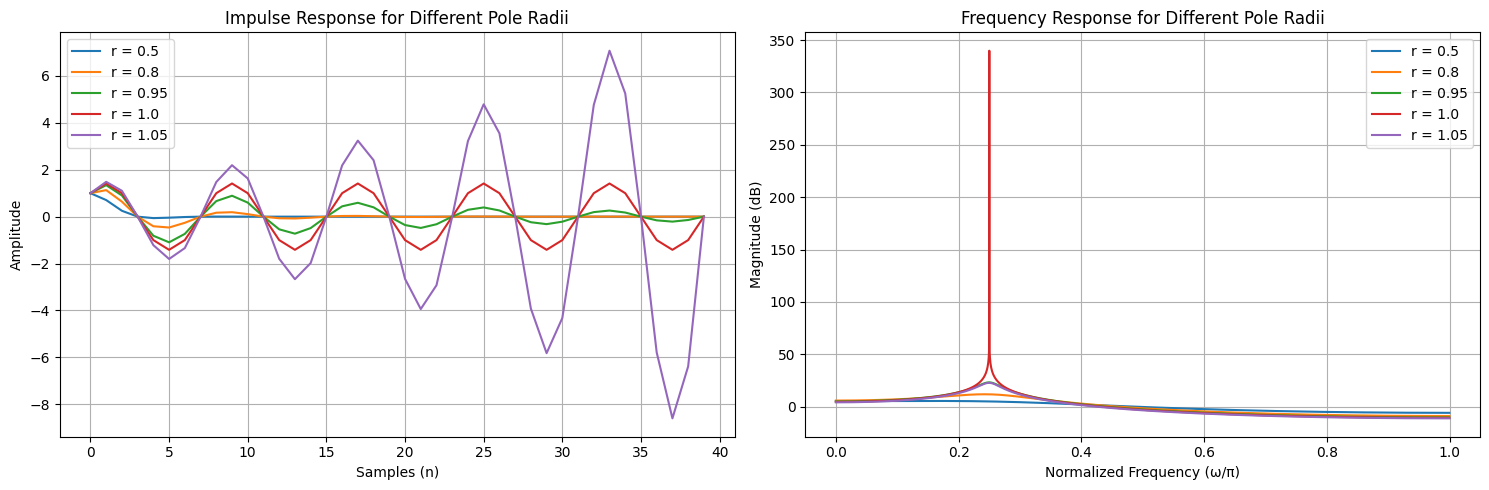

In [6]:
# TASK 4.3: Effect of Pole Radius on System Response

# Different pole radius values
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Sampling points
n = np.arange(40)

# Create unit impulse
impulse = np.zeros(40)
impulse[0] = 1

# Create two plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for r in r_values:

    # Calculate denominator coefficients
    a = [1, -2*r*np.cos(np.pi/4), r**2]

    # Calculate impulse response
    h = signal.lfilter([1], a, impulse)

    # Plot impulse response
    ax1.plot(n, h, label=f"r = {r}")

    # Calculate frequency response
    w, H = signal.freqz([1], a, worN=2048)

    # Convert magnitude to decibels
    magnitude_db = 20 * np.log10(np.maximum(np.abs(H), 1e-12))

    # Plot frequency response
    ax2.plot(w/np.pi, magnitude_db, label=f"r = {r}")

# Format impulse response plot
ax1.set_title("Impulse Response for Different Pole Radii")
ax1.set_xlabel("Samples (n)")
ax1.set_ylabel("Amplitude")
ax1.grid()
ax1.legend()

# Format frequency response plot
ax2.set_title("Frequency Response for Different Pole Radii")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()
ax2.legend()

plt.tight_layout()
plt.show()

### Observation — Task 4.3

The impulse and frequency responses were plotted for different pole radius values.

When r = 0.5, the impulse response decayed quickly.

As the pole radius increased towards 1, the signal decayed more slowly and the resonance peak became sharper.

When r = 1.0, the impulse response produced sustained oscillations because the poles were located on the unit circle.

When r = 1.05, the oscillations increased in amplitude, indicating an unstable system.

This experiment demonstrates that pole radius affects the decay rate, resonance and stability of a digital system.

H1
Poles: [0.8+0.5j 0.8-0.5j]
Classification: STABLE
----------------------------------------
H2
Poles: [2.  0.5]
Classification: NOT BIBO STABLE
----------------------------------------
H3
Poles: [-1.   0.5]
Classification: NOT BIBO STABLE
----------------------------------------
H4
Poles: []
Classification: STABLE
----------------------------------------


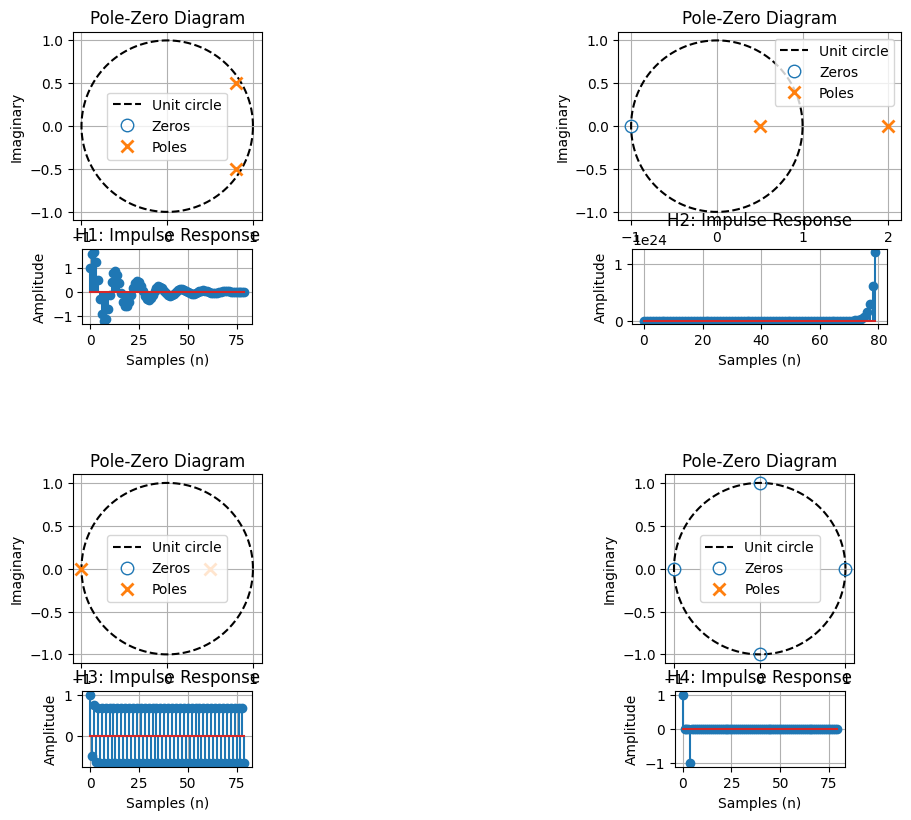

In [7]:
# TASK 4.4: Stability Classification

# Define four systems
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

# Generate unit impulse
N = 80
impulse = np.zeros(N)
impulse[0] = 1

# Create plots
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Analyze each system
for (name, (b, a)), ax in zip(systems.items(), axes.flat):

    # Calculate zeros and poles
    z, p = zplane(b, a, ax)

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Check stability
    stable = np.all(np.abs(p) < 1)

    # Display impulse response
    ax_response = ax.inset_axes([0.05, -0.55, 0.9, 0.4])
    ax_response.stem(np.arange(N), h)
    ax_response.set_title(f"{name}: Impulse Response")
    ax_response.set_xlabel("Samples (n)")
    ax_response.set_ylabel("Amplitude")
    ax_response.grid()

    # Print results
    if stable:
        classification = "STABLE"
    else:
        classification = "NOT BIBO STABLE"

    print(f"{name}")
    print("Poles:", p)
    print("Classification:", classification)
    print("-" * 40)

plt.tight_layout()
plt.show()

### Observation — Task 4.4

The pole-zero diagrams and impulse responses of four systems were analyzed using Python and SciPy.

System H1 was classified as stable because its poles were 0.8 + 0.5j and 0.8 - 0.5j. Both poles are inside the unit circle.

System H2 was classified as not BIBO stable because it has poles at 2.0 and 0.5. The pole at 2.0 is outside the unit circle.

System H3 was classified as not BIBO stable because it has a pole at -1.0, which lies exactly on the unit circle. The other pole is at 0.5.

System H4 was classified as stable because it is an FIR system and has no finite poles.

The results demonstrate that pole locations determine the stability of digital systems.

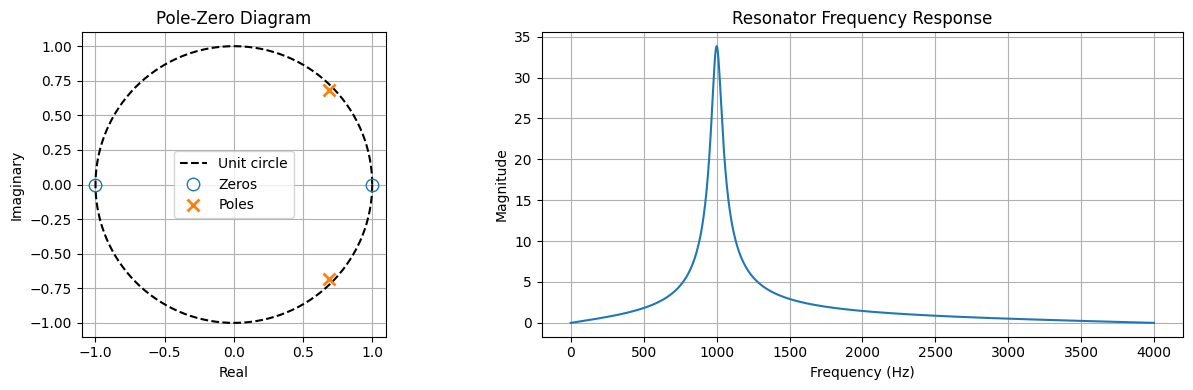

Sampling frequency: 8000 Hz
Resonance frequency: 1000 Hz
Pole radius: 0.97
Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Stable: True


In [8]:
# TASK 4.5: Design a Second-Order Resonator

# Given parameters
fs = 8000
f0 = 1000
r = 0.97

# Calculate resonant frequency angle
theta = 2 * np.pi * f0 / fs

# Numerator: zeros at z = +1 and z = -1
b = [1, 0, -1]

# Denominator: poles at radius r
a = [1, -2*r*np.cos(theta), r**2]

# Calculate frequency response
f, H = signal.freqz(b, a, fs=fs, worN=2048)

# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

# Plot pole-zero diagram
z, p = zplane(b, a, ax1)

# Plot frequency response
ax2.plot(f, np.abs(H))
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude")
ax2.grid()

plt.tight_layout()
plt.show()

# Display system information
print("Sampling frequency:", fs, "Hz")
print("Resonance frequency:", f0, "Hz")
print("Pole radius:", r)
print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

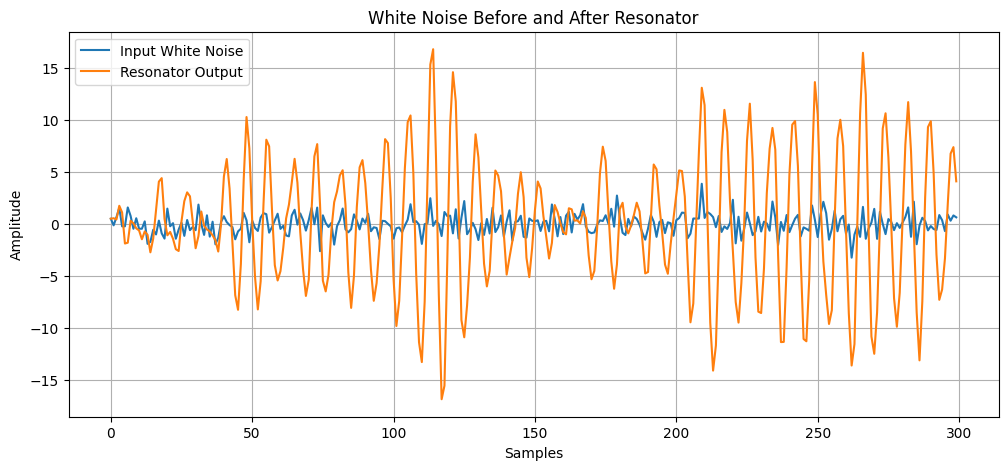

Input signal length: 8000
Output signal length: 8000


In [9]:
# Generate white noise
np.random.seed(42)
noise = np.random.randn(fs)

# Apply the resonator
y = signal.lfilter(b, a, noise)

# Plot input and output signals
plt.figure(figsize=(12, 5))

plt.plot(noise[:300], label="Input White Noise")
plt.plot(y[:300], label="Resonator Output")

plt.title("White Noise Before and After Resonator")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

print("Input signal length:", len(noise))
print("Output signal length:", len(y))

In [10]:
from IPython.display import Audio, display

display(Audio(y, rate=fs))

### Observation — Task 4.5

A second-order resonator was successfully designed with a resonance frequency of 1000 Hz and a pole radius of 0.97.

The system has zeros at z = +1 and z = -1, which block DC and Nyquist frequencies.

The frequency response showed a peak around 1000 Hz, confirming the resonator's operating frequency.

White noise was passed through the resonator using the lfilter function. The output emphasized frequencies around the resonant frequency.

The system was stable because both poles were inside the unit circle.

# CHECKPOINT 4

## Task 4.4: Stability Classification

The stability results obtained were:

| System | Poles | Classification |
|---|---|---|
| H1 | 0.8 + 0.5j, 0.8 - 0.5j | Stable |
| H2 | 2.0, 0.5 | Not BIBO stable |
| H3 | -1.0, 0.5 | Not BIBO stable |
| H4 | No finite poles | Stable |

## Task 4.5: Resonator Design

A second-order resonator was designed using the following parameters:

- Sampling frequency: 8000 Hz
- Resonance frequency: 1000 Hz
- Pole radius: 0.97
- Zeros: z = +1 and z = -1

The frequency response was plotted and white noise was passed through the resonator.

The system was stable because its poles were inside the unit circle.

# ANALYSIS QUESTIONS

### Question 1: How does the pole radius r affect the bandwidth of the resonance in Task 4.3?

The pole radius affects the bandwidth of the resonance.

When r is small, the bandwidth is wider and the impulse response decays quickly.

When r approaches 1, the bandwidth becomes narrower and the resonance peak becomes sharper. The impulse response also decays more slowly.

### Question 2: What happens to h(n) when a pole lies exactly on the unit circle?

When a pole lies exactly on the unit circle, the impulse response does not decay to zero.

It produces sustained oscillations or a constant-amplitude response. Therefore, the system is not BIBO stable.

### Question 3: Why do zeros at z = +1 and z = -1 make the resonator a band-pass filter?

The zero at z = +1 blocks the DC frequency (0 Hz).

The zero at z = -1 blocks the Nyquist frequency (4000 Hz for an 8000 Hz sampling frequency).

These zeros reduce the response at the two frequency limits while allowing frequencies around 1000 Hz to pass.

Therefore, the resonator behaves like a band-pass filter.

### Question 4: Use the stability triangle to check systems H1, H2 and H3.

For a second-order system with denominator:

1 + a1z^-1 + a2z^-2

The stability conditions are:

1. |a2| < 1
2. 1 + a1 + a2 > 0
3. 1 - a1 + a2 > 0

**System H1:**

a1 = -1.6 and a2 = 0.89

|0.89| < 1

1 - 1.6 + 0.89 = 0.29 > 0

1 + 1.6 + 0.89 = 3.49 > 0

All conditions are satisfied. Therefore, H1 is stable.

**System H2:**

a1 = -2.5 and a2 = 1

|1| < 1 is false.

Therefore, H2 is not stable.

**System H3:**

a1 = 0.5 and a2 = -0.5

|-0.5| < 1

1 + 0.5 - 0.5 = 1 > 0

1 - 0.5 - 0.5 = 0

The third condition is not strictly greater than zero. Therefore, H3 lies on the stability boundary and is not BIBO stable.

# AI USE STATEMENT

Artificial Intelligence (AI) was used as a learning and support tool during this laboratory exercise.

It assisted in explaining z-transform concepts, understanding Python and SciPy functions, debugging code, and interpreting experimental results.

All code was executed in Google Colab, and the results were reviewed and used to prepare the observations and analysis answers.

AI was used to support learning and understanding of the laboratory activities.